<a href="https://colab.research.google.com/github/Erick88santos/Dataset_shark_anotation/blob/main/ESTUDO_DE_CASO_DRONESHARK_DATASET_VALIDACAO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Estudo de Caso — DroneShark Dataset

## Avaliação da capacidade de detecção de tubarões em diferentes condições ambientais

Este notebook foi reorganizado para utilizar **um único modelo YOLO11s** como instrumento experimental. O objetivo não é comparar versões do YOLO, mas avaliar como diferentes condições visuais presentes nas imagens aéreas influenciam a detecção.

Fluxo:

**Dataset → preparação → train/val/test → YOLO11s → avaliação geral → classificação das condições → avaliação por condição → análise visual → vídeo**


## 1. Configuração do ambiente

Esta célula instala as bibliotecas utilizadas no experimento.


In [1]:
# Instalação das bibliotecas
!pip install -q ultralytics opencv-python pandas matplotlib seaborn pyyaml

# Se estiver usando Google Drive, descomente:
# from google.colab import drive
# drive.mount('/content/drive')


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.7/45.7 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 37.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.3/65.3 kB 6.7 MB/s eta 0:00:00


In [2]:
# Importações e configuração reprodutível
import os
import random
import shutil
import zipfile
import glob
import yaml
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from ultralytics import YOLO

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Ambiente configurado.")


Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.
Ambiente configurado.


## 2. Verificação da GPU

O treinamento será executado no Google Colab utilizando GPU quando disponível.


In [3]:
!nvidia-smi


Mon Aug 24 13:27:47 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [4]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA disponível:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("ATENÇÃO: GPU não disponível. No Colab, selecione Runtime > Change runtime type > GPU.")


PyTorch: 2.11.0+cu128
CUDA disponível: True
GPU: Tesla T4


## 3. Localização do dataset

### Opção A — dataset já está em `/content`

Se você já possui uma pasta com `images/` e `labels/`, altere `SOURCE_DATASET`.

### Opção B — dataset em arquivo ZIP

Execute a célula de upload e envie o `.zip` do DroneShark Dataset.

A estrutura esperada da fonte é:

```text
fonte_do_dataset/
├── images/
│   ├── imagem1.jpg
│   ├── imagem2.jpg
│   └── ...
└── labels/
    ├── imagem1.txt
    ├── imagem2.txt
    └── ...
```

O script também aceita uma fonte que já possua `train/`, `val/` e `test/`.


In [5]:
# ===== CONFIGURAÇÃO =====
# Caminho para o arquivo ZIP do dataset (se for o caso)
ZIP_FILE_PATH = "/content/YOLO_DATA.zip"

# Pasta onde o dataset será extraído e que conterá images/ e labels/
EXTRACTED_DATASET_ROOT = "/content/droneshark_dataset_extracted"

# A variável SOURCE_DATASET será definida dinamicamente após a extração
# ou se o dataset já estiver em uma pasta com images/ e labels/
SOURCE_DATASET = EXTRACTED_DATASET_ROOT # Define um valor inicial para referência

# Pasta final utilizada pelo experimento (para a divisão train/val/test)
DATASET = "/content/dataset"

# Classes utilizadas no estudo de caso
CLASS_NAMES = ["human-bather", "human-surfist", "shark"]
SHARK_CLASS_ID = 2

print("ZIP_FILE_PATH:", ZIP_FILE_PATH)
print("EXTRACTED_DATASET_ROOT:", EXTRACTED_DATASET_ROOT)
print("DATASET (para splits):", DATASET)


ZIP_FILE_PATH: /content/YOLO_DATA.zip
EXTRACTED_DATASET_ROOT: /content/droneshark_dataset_extracted
DATASET (para splits): /content/dataset


In [7]:
# ===== EXTRAÇÃO/VERIFICAÇÃO DO DATASET =====

from google.colab import files

# Função auxiliar para encontrar a pasta raiz do dataset (com 'images' e 'labels')
def find_dataset_root(base_path):
    base_path = Path(base_path)
    if base_path.is_dir() and (base_path / "images").is_dir() and (base_path / "labels").is_dir():
        return str(base_path)

    # Procura um nível mais profundo por um padrão comum (ex: dataset.zip/dataset_folder/images)
    for root, dirs, _ in os.walk(base_path):
        current_path = Path(root)
        if (current_path / "images").is_dir() and (current_path / "labels").is_dir():
            return str(current_path)
    return None

# Variável para armazenar o caminho final do dataset (onde estão images/ e labels/)
final_source_dataset = None

# 1. Tenta encontrar o dataset já extraído em EXTRACTED_DATASET_ROOT
found_in_extracted = find_dataset_root(EXTRACTED_DATASET_ROOT)
if found_in_extracted:
    final_source_dataset = found_in_extracted
    print(f"Dataset encontrado e já extraído em: {final_source_dataset}")
else:
    # 2. Se não estiver extraído, tenta extrair do ZIP_FILE_PATH
    if os.path.exists(ZIP_FILE_PATH):
        print(f"Extraindo dataset de {ZIP_FILE_PATH} para {EXTRACTED_DATASET_ROOT}...")
        os.makedirs(EXTRACTED_DATASET_ROOT, exist_ok=True)
        with zipfile.ZipFile(ZIP_FILE_PATH, "r") as z:
            z.extractall(EXTRACTED_DATASET_ROOT)

        final_source_dataset = find_dataset_root(EXTRACTED_DATASET_ROOT)
        if final_source_dataset:
            print(f"Dataset extraído e encontrado em: {final_source_dataset}")
        else:
            raise FileNotFoundError(
                "O arquivo ZIP foi extraído, mas não foi encontrada uma estrutura images/ + labels/ válida."+
                "Verifique se o ZIP contém uma pasta com 'images/' e 'labels/' dentro de si."
            )
    else:
        # 3. Se o ZIP não existe, solicita upload
        print("Arquivo ZIP do dataset não encontrado.")
        print("Envie agora o ZIP do dataset.")
        uploaded = files.upload()

        zip_files = [name for name in uploaded if name.lower().endswith(".zip")]
        if not zip_files:
            raise FileNotFoundError("Nenhum arquivo .zip foi enviado.")

        uploaded_zip_path = "/content/" + zip_files[0]
        print(f"Extraindo dataset de {uploaded_zip_path} para {EXTRACTED_DATASET_ROOT}...")
        os.makedirs(EXTRACTED_DATASET_ROOT, exist_ok=True)
        with zipfile.ZipFile(uploaded_zip_path, "r") as z:
            z.extractall(EXTRACTED_DATASET_ROOT)

        final_source_dataset = find_dataset_root(EXTRACTED_DATASET_ROOT)
        if final_source_dataset:
            print(f"Dataset extraído e encontrado em: {final_source_dataset}")
        else:
            raise FileNotFoundError(
                "O arquivo ZIP foi extraído, mas não foi encontrada uma estrutura images/ + labels/ válida."+
                "Verifique se o ZIP contém uma pasta com 'images/' e 'labels/' dentro de si."
            )

if not final_source_dataset:
    raise FileNotFoundError("Não foi possível encontrar ou extrair o dataset.")

# Atualiza a variável global SOURCE_DATASET para ser usada nas próximas células
SOURCE_DATASET = final_source_dataset
print("\nSOURCE_DATASET atualizado para:", SOURCE_DATASET)


Extraindo dataset de /content/YOLO_DATA.zip para /content/droneshark_dataset_extracted...
Dataset extraído e encontrado em: /content/droneshark_dataset_extracted

SOURCE_DATASET atualizado para: /content/droneshark_dataset_extracted


## 4. Validação da estrutura e das classes

Antes de treinar, esta etapa verifica se as imagens possuem seus respectivos arquivos de anotação YOLO e mostra a distribuição das classes.


In [8]:
# Extensões aceitas
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def find_image_label_pairs(root):
    root = Path(root)
    image_files = [
        p for p in root.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS
        and "images" in [part.lower() for part in p.parts]
    ]

    pairs = []
    missing = []

    for img in image_files:
        parts = list(img.parts)
        idx = [p.lower() for p in parts].index("images")
        label_parts = parts[:idx] + ["labels"] + parts[idx+1:]
        label_path = Path(*label_parts).with_suffix(".txt")

        if label_path.exists():
            pairs.append((img, label_path))
        else:
            missing.append((img, label_path))

    return pairs, missing

pairs, missing = find_image_label_pairs(SOURCE_DATASET)

print("Pares imagem/label encontrados:", len(pairs))
print("Imagens sem label:", len(missing))

if missing:
    print("\nExemplos de arquivos sem anotação:")
    for img, label in missing[:10]:
        print(" -", img)


Pares imagem/label encontrados: 449
Imagens sem label: 0


In [9]:
from pathlib import Path
import shutil

# ============================================================
# CONFIGURAÇÃO
# ============================================================

SOURCE_DIR = Path("/content/droneshark_dataset_extracted")

SOURCE_IMAGES = SOURCE_DIR / "images"
SOURCE_LABELS = SOURCE_DIR / "labels"

OUTPUT_DIR = Path("/content/droneshark_dataset_3classes")

OUTPUT_IMAGES = OUTPUT_DIR / "images"
OUTPUT_LABELS = OUTPUT_DIR / "labels"

# ============================================================
# MAPEAMENTO DAS CLASSES
# ============================================================

# Classe original → classe final
CLASS_MAPPING = {
    0: 0,  # human-bather
    1: 1,  # human-surfist
    3: 2   # shark
}

CLASS_NAMES = [
    "human-bather",
    "human-surfist",
    "shark"
]

# ============================================================
# CRIAR DIRETÓRIOS
# ============================================================

OUTPUT_IMAGES.mkdir(parents=True, exist_ok=True)
OUTPUT_LABELS.mkdir(parents=True, exist_ok=True)

# ============================================================
# EXTENSÕES DE IMAGEM
# ============================================================

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}

# ============================================================
# CONTADORES
# ============================================================

total_images = 0
total_annotations = 0
kept_annotations = 0
removed_annotations = 0

class_counts = {
    0: 0,
    1: 0,
    2: 0
}

# ============================================================
# PROCESSAMENTO
# ============================================================

for image_path in SOURCE_IMAGES.iterdir():

    if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
        continue

    total_images += 1

    # Copiar imagem
    output_image = OUTPUT_IMAGES / image_path.name
    shutil.copy2(image_path, output_image)

    # Label correspondente
    label_path = SOURCE_LABELS / f"{image_path.stem}.txt"
    output_label = OUTPUT_LABELS / f"{image_path.stem}.txt"

    new_lines = []

    if label_path.exists():

        lines = label_path.read_text(
            encoding="utf-8"
        ).splitlines()

        for line in lines:

            line = line.strip()

            if not line:
                continue

            parts = line.split()

            if len(parts) < 5:
                continue

            try:
                original_class = int(float(parts[0]))
            except ValueError:
                continue

            total_annotations += 1

            # ==================================================
            # VERIFICA SE A CLASSE SERÁ MANTIDA
            # ==================================================

            if original_class in CLASS_MAPPING:

                new_class = CLASS_MAPPING[original_class]

                # Substitui somente o ID da classe
                new_line = " ".join(
                    [str(new_class)] + parts[1:]
                )

                new_lines.append(new_line)

                kept_annotations += 1
                class_counts[new_class] += 1

            else:

                # other-fish, turtle e whale
                removed_annotations += 1

    # ==========================================================
    # SALVAR NOVO LABEL
    # ==========================================================

    output_label.write_text(
        "\n".join(new_lines),
        encoding="utf-8"
    )

# ============================================================
# RESULTADO
# ============================================================

print("=" * 60)
print("DATASET FILTRADO E REMAPEADO")
print("=" * 60)

print(f"\nImagens processadas: {total_images}")

print("\nDistribuição FINAL das instâncias:")

for class_id, count in class_counts.items():
    print(
        f"{class_id} - {CLASS_NAMES[class_id]}: {count}"
    )

print("\nAnotações:")
print(f"Total original: {total_annotations}")
print(f"Anotações mantidas: {kept_annotations}")
print(f"Anotações removidas: {removed_annotations}")

print("\nMapeamento utilizado:")

print("0 human-bather  → 0 human-bather")
print("1 human-surfist → 1 human-surfist")
print("2 other-fish    → REMOVIDO")
print("3 shark         → 2 shark")
print("4 turtle        → REMOVIDO")
print("5 whale         → REMOVIDO")

print(f"\nNovo dataset:")
print(OUTPUT_DIR)

DATASET FILTRADO E REMAPEADO

Imagens processadas: 449

Distribuição FINAL das instâncias:
0 - human-bather: 99
1 - human-surfist: 100
2 - shark: 811

Anotações:
Total original: 1041
Anotações mantidas: 1010
Anotações removidas: 31

Mapeamento utilizado:
0 human-bather  → 0 human-bather
1 human-surfist → 1 human-surfist
2 other-fish    → REMOVIDO
3 shark         → 2 shark
4 turtle        → REMOVIDO
5 whale         → REMOVIDO

Novo dataset:
/content/droneshark_dataset_3classes


In [10]:
from pathlib import Path

LABELS_DIR = Path(
    "/content/droneshark_dataset_3classes/labels"
)

CLASS_NAMES = [
    "human-bather",
    "human-surfist",
    "shark"
]

class_counts = {
    i: 0 for i in range(len(CLASS_NAMES))
}

invalid_labels = []

for label_path in LABELS_DIR.glob("*.txt"):

    try:

        lines = label_path.read_text(
            encoding="utf-8"
        ).strip().splitlines()

        for line in lines:

            if not line.strip():
                continue

            parts = line.split()

            # YOLO bbox precisa de:
            # class x_center y_center width height
            if len(parts) != 5:

                invalid_labels.append(
                    (
                        label_path,
                        line,
                        "Formato inválido"
                    )
                )

                continue

            try:
                cls = int(float(parts[0]))

                coords = [
                    float(x)
                    for x in parts[1:]
                ]

            except ValueError:

                invalid_labels.append(
                    (
                        label_path,
                        line,
                        "Valores não numéricos"
                    )
                )

                continue

            # Verificar classe
            if cls < 0 or cls >= len(CLASS_NAMES):

                invalid_labels.append(
                    (
                        label_path,
                        line,
                        f"ID de classe ({cls}) fora "
                        f"do range [0, {len(CLASS_NAMES)-1}]"
                    )
                )

                continue

            # Verificar coordenadas YOLO
            if not all(
                0 <= value <= 1
                for value in coords
            ):

                invalid_labels.append(
                    (
                        label_path,
                        line,
                        "Coordenadas fora do intervalo [0,1]"
                    )
                )

                continue

            class_counts[cls] += 1

    except Exception as e:

        invalid_labels.append(
            (
                label_path,
                str(e),
                "Erro de leitura"
            )
        )


print("Distribuição FINAL de instâncias:")

for cls_id, count in class_counts.items():

    print(
        f"{cls_id} - "
        f"{CLASS_NAMES[cls_id]}: "
        f"{count}"
    )


print(
    "\nAnotações inválidas:",
    len(invalid_labels)
)


if invalid_labels:

    print(
        "\nExemplos de anotações inválidas:"
    )

    for item in invalid_labels[:10]:

        print(item)

Distribuição FINAL de instâncias:
0 - human-bather: 99
1 - human-surfist: 100
2 - shark: 807

Anotações inválidas: 4

Exemplos de anotações inválidas:
(PosixPath('/content/droneshark_dataset_3classes/labels/26bb7808-00605.txt'), '2 0.3195663266135246 1.1622447637798778 0.20758861278614305 0.5738364298027224', 'Coordenadas fora do intervalo [0,1]')
(PosixPath('/content/droneshark_dataset_3classes/labels/5e88bcfa-00593.txt'), '2 0.7300035026674543 1.0431454941219767 0.15497366594300685 0.545924338030236', 'Coordenadas fora do intervalo [0,1]')
(PosixPath('/content/droneshark_dataset_3classes/labels/95c5fbf5-00621.txt'), '2 0.49159579020807703 1.172674944304481 0.16502575616951834 0.630196936542675', 'Coordenadas fora do intervalo [0,1]')
(PosixPath('/content/droneshark_dataset_3classes/labels/876f2af9-00216.txt'), '2 0.7581150614338906 1.0335302131046256 0.06499999999999972 0.32966960750717106', 'Coordenadas fora do intervalo [0,1]')


In [11]:
from pathlib import Path

LABELS_DIR = Path(
    "/content/droneshark_dataset_3classes/labels"
)

removed = 0

for label_path in LABELS_DIR.glob("*.txt"):

    lines = label_path.read_text(
        encoding="utf-8"
    ).splitlines()

    valid_lines = []

    for line in lines:

        line = line.strip()

        if not line:
            continue

        parts = line.split()

        if len(parts) != 5:
            continue

        try:
            cls = int(float(parts[0]))
            coords = [float(x) for x in parts[1:]]

        except ValueError:
            continue

        # Verifica classe
        if cls < 0 or cls >= 3:
            removed += 1
            continue

        # Verifica coordenadas
        if not all(0 <= value <= 1 for value in coords):
            print(
                f"Removendo anotação inválida: "
                f"{label_path.name}"
            )

            removed += 1
            continue

        valid_lines.append(line)

    # Reescreve o arquivo
    label_path.write_text(
        "\n".join(valid_lines),
        encoding="utf-8"
    )

print()
print(f"Anotações inválidas removidas: {removed}")

Removendo anotação inválida: 26bb7808-00605.txt
Removendo anotação inválida: 5e88bcfa-00593.txt
Removendo anotação inválida: 95c5fbf5-00621.txt
Removendo anotação inválida: 876f2af9-00216.txt

Anotações inválidas removidas: 4


In [12]:
from pathlib import Path
from collections import Counter

LABELS_DIR = Path(
    "/content/droneshark_dataset_3classes/labels"
)

CLASS_NAMES = [
    "human-bather",
    "human-surfist",
    "shark"
]

class_counts = Counter()
invalid_labels = []
empty_labels = 0
total_label_files = 0

for label_path in LABELS_DIR.glob("*.txt"):

    total_label_files += 1

    lines = label_path.read_text(
        encoding="utf-8"
    ).strip().splitlines()

    valid_lines = 0

    for line_number, line in enumerate(lines, start=1):

        if not line.strip():
            continue

        parts = line.split()

        # YOLO Detection:
        # class x_center y_center width height
        if len(parts) != 5:

            invalid_labels.append(
                (
                    label_path.name,
                    line_number,
                    line,
                    "Formato inválido"
                )
            )

            continue

        try:
            cls = int(float(parts[0]))

            coords = [
                float(value)
                for value in parts[1:]
            ]

        except ValueError:

            invalid_labels.append(
                (
                    label_path.name,
                    line_number,
                    line,
                    "Valor não numérico"
                )
            )

            continue

        # Classe
        if cls < 0 or cls >= len(CLASS_NAMES):

            invalid_labels.append(
                (
                    label_path.name,
                    line_number,
                    line,
                    f"Classe {cls} fora do intervalo"
                )
            )

            continue

        # Coordenadas
        if not all(
            0 <= value <= 1
            for value in coords
        ):

            invalid_labels.append(
                (
                    label_path.name,
                    line_number,
                    line,
                    "Coordenada fora de [0,1]"
                )
            )

            continue

        class_counts[cls] += 1
        valid_lines += 1

    if valid_lines == 0:
        empty_labels += 1


# ============================================================
# RESULTADO
# ============================================================

print("=" * 60)
print("VALIDAÇÃO FINAL DO DATASET")
print("=" * 60)

print(f"\nArquivos de labels: {total_label_files}")
print(f"Labels vazios: {empty_labels}")

print("\nDistribuição de instâncias:")

total_instances = 0

for cls_id, class_name in enumerate(CLASS_NAMES):

    count = class_counts[cls_id]

    total_instances += count

    print(
        f"{cls_id} - {class_name}: {count}"
    )

print(f"\nTotal de instâncias válidas: {total_instances}")

print(
    f"\nAnotações inválidas: "
    f"{len(invalid_labels)}"
)

if invalid_labels:

    print("\nExemplos:")

    for item in invalid_labels[:10]:
        print(item)

else:

    print(
        "\n✅ DATASET VALIDADO COM SUCESSO!"
    )

VALIDAÇÃO FINAL DO DATASET

Arquivos de labels: 449
Labels vazios: 5

Distribuição de instâncias:
0 - human-bather: 99
1 - human-surfist: 100
2 - shark: 807

Total de instâncias válidas: 1006

Anotações inválidas: 0

✅ DATASET VALIDADO COM SUCESSO!


## 5. Divisão reprodutível: 70% treino, 15% validação e 15% teste

A divisão é feita uma única vez com `SEED = 42`.

**Importante:** o conjunto de teste não será utilizado para escolher hiperparâmetros. Ele será reservado para a avaliação final.


In [13]:
# ===== DIVISÃO TRAIN / VAL / TEST E PROCESSAMENTO DE LABELS =====

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

assert abs(TRAIN_RATIO + VAL_RATIO + TEST_RATIO - 1.0) < 1e-9

# Faz uma cópia dos pares para usar na divisão
# `pairs` deve ter sido populado pela célula Lx85ahhhVpgI
all_pairs = pairs.copy()
rng = random.Random(SEED)
rng.shuffle(all_pairs)

n = len(all_pairs)
n_train = int(n * TRAIN_RATIO)
n_val = int(n * VAL_RATIO)

splits = {
    "train": all_pairs[:n_train],
    "val": all_pairs[n_train:n_train+n_val],
    "test": all_pairs[n_train+n_val:]
}

# Recria o dataset experimental
if os.path.exists(DATASET):
    shutil.rmtree(DATASET)

# Cria os diretórios necessários para a nova estrutura do dataset
for split_name in ["train", "val", "test"]:
    os.makedirs(f"{DATASET}/images/{split_name}", exist_ok=True)
    os.makedirs(f"{DATASET}/labels/{split_name}", exist_ok=True)

# Variável para contar anotações remapeadas
remapped_annotations_count = 0

# Copia os arquivos para os novos diretórios, processando os labels
for split_name, split_pairs in splits.items():
    for img_path, label_path in split_pairs:
        # Copia a imagem
        shutil.copy2(img_path, f"{DATASET}/images/{split_name}/{img_path.name}")

        # Lê o conteúdo do label original
        original_label_content = label_path.read_text(encoding="utf-8")
        processed_label_lines = []

        for line in original_label_content.strip().splitlines():
            if not line.strip():
                continue
            parts = line.split()
            if len(parts) > 0:
                # Converte o primeiro elemento para int (class_id)
                try:
                    cls_id = int(float(parts[0]))
                    # Remapeia qualquer class_id fora do range para SHARK_CLASS_ID (2)
                    if cls_id >= len(CLASS_NAMES):
                        parts[0] = str(SHARK_CLASS_ID) # SHARK_CLASS_ID é 2
                        remapped_annotations_count += 1
                    processed_label_lines.append(" ".join(parts))
                except ValueError:
                    # Se não conseguir converter para float/int, mantém a linha como está ou descarta
                    # Para este caso, vamos manter a linha, mas é uma anotação malformada
                    processed_label_lines.append(line)
            else:
                processed_label_lines.append(line)

        # Salva o label processado no novo diretório
        with open(f"{DATASET}/labels/{split_name}/{label_path.name}", "w", encoding="utf-8") as f:
            f.write("\n".join(processed_label_lines))

print("Divisão e processamento de labels concluídos:")
for split_name, items in splits.items():
    print(f"  {split_name}: {len(items)} imagens")
print(f"Total de anotações remapeadas (class_id >={len(CLASS_NAMES)} -> {SHARK_CLASS_ID}): {remapped_annotations_count}")

Divisão e processamento de labels concluídos:
  train: 314 imagens
  val: 67 imagens
  test: 68 imagens
Total de anotações remapeadas (class_id >=3 -> 2): 830


In [14]:
# Criar data.yaml
DATA_YAML = f"{DATASET}/data.yaml"

yaml_data = {
    "path": DATASET,
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": len(CLASS_NAMES),
    "names": CLASS_NAMES
}

with open(DATA_YAML, "w", encoding="utf-8") as f:
    yaml.safe_dump(yaml_data, f, sort_keys=False, allow_unicode=True)

print(open(DATA_YAML, encoding="utf-8").read())


path: /content/dataset
train: images/train
val: images/val
test: images/test
nc: 3
names:
- human-bather
- human-surfist
- shark



In [15]:
# ============================================================
# LOCALIZAR AUTOMATICAMENTE O CONJUNTO DE TESTE
# ============================================================

from pathlib import Path

# Procura diretórios contendo images/test e labels/test
candidatos = []

for images_test in Path("/content").rglob("images/test"):
    dataset_root = images_test.parent.parent
    labels_test = dataset_root / "labels" / "test"

    if labels_test.exists():
        candidatos.append({
            "dataset_root": str(dataset_root),
            "images_test": str(images_test),
            "labels_test": str(labels_test)
        })

print("=" * 70)
print("POSSÍVEIS DATASETS COM CONJUNTO TEST")
print("=" * 70)

for i, item in enumerate(candidatos):
    print(f"\n[{i}]")
    print("Dataset:", item["dataset_root"])
    print("Images :", item["images_test"])
    print("Labels :", item["labels_test"])

POSSÍVEIS DATASETS COM CONJUNTO TEST

[0]
Dataset: /content/dataset
Images : /content/dataset/images/test
Labels : /content/dataset/labels/test


## 6. Conferência visual da base

Antes do treinamento, é recomendável visualizar algumas imagens com suas anotações.


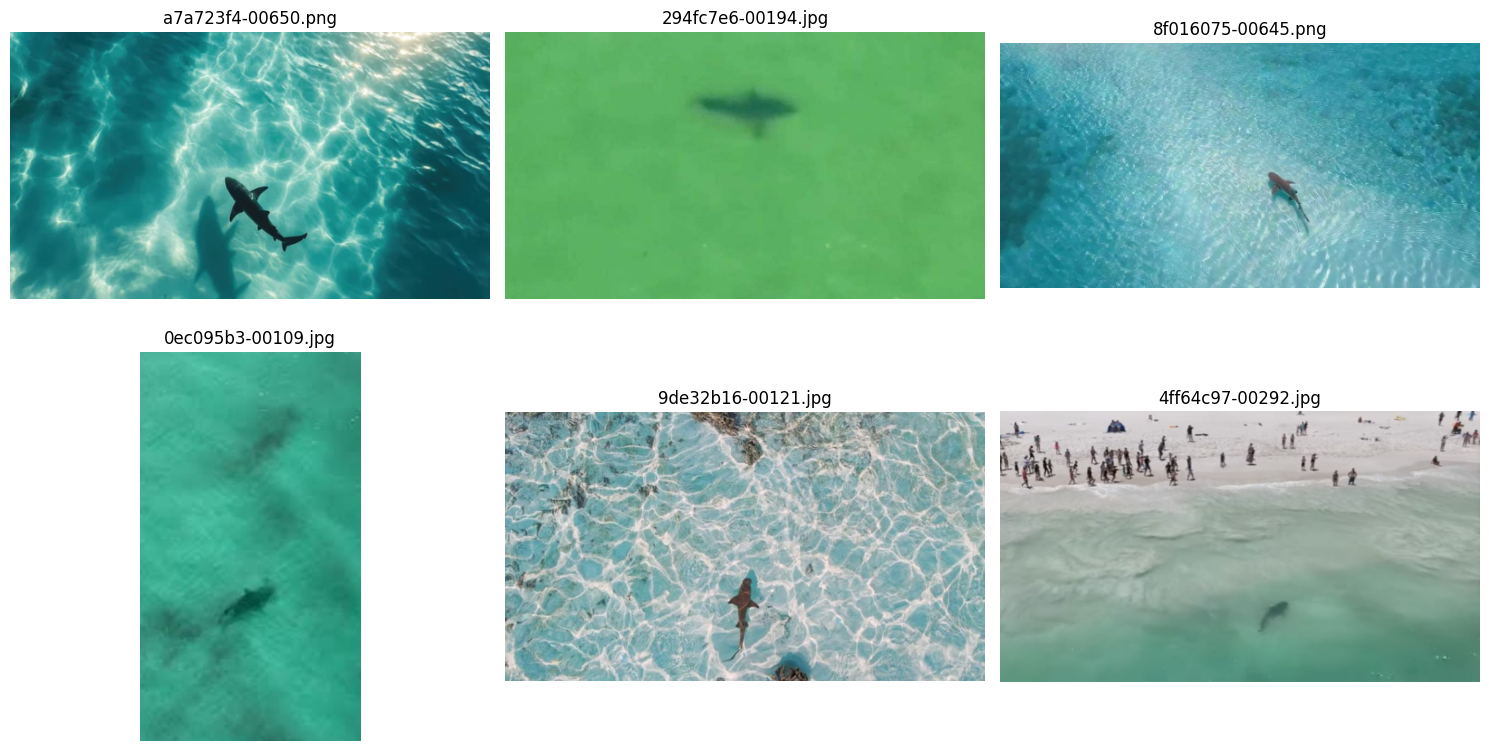

In [16]:
# Visualiza algumas imagens do conjunto de treino
def show_samples(split="train", n=6):
    image_files = [
        p for p in Path(f"{DATASET}/images/{split}").iterdir()
        if p.suffix.lower() in IMAGE_EXTS
    ]
    random.Random(SEED).shuffle(image_files)
    image_files = image_files[:n]

    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    axes = axes.ravel()

    for ax in axes:
        ax.axis("off")

    for ax, img_path in zip(axes, image_files):
        img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
        ax.imshow(img)
        ax.set_title(img_path.name)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

show_samples("train", 6)


## 7. Treinamento do YOLO11s

Nesta nova estratégia será utilizado **um único modelo**, YOLO11s.

A intenção é manter o protocolo controlado. Não serão feitos vários treinamentos com diferentes versões do YOLO para decidir qual é a melhor. O modelo será utilizado como instrumento para investigar o efeito das condições visuais.


In [17]:
# ===== TREINAMENTO =====

from ultralytics import YOLO

model = YOLO("yolo11s.pt")

results = model.train(
    data=DATA_YAML,
    epochs=100,
    imgsz=640,
    batch=16,
    workers=0,
    patience=20,
    seed=SEED,
    project="/content/results",
    name="drone_shark_yolo11s_v2",
    exist_ok=True,
    device=0
)

BEST_MODEL = "/content/results/drone_shark_yolo11s_v2/weights/best.pt"

print("Melhor modelo:", BEST_MODEL)

Ultralytics 8.4.127 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=drone_shark_yolo11s_v2, nbs=64, nm

## 8. Curvas de treinamento

O YOLO salva os resultados em `results.csv` e gera gráficos na pasta do experimento.


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
68,69,799.815,1.31266,0.90011,1.24468,0.74162,0.64051,0.66126,0.30321,2.06492,1.59683,1.77495,0.000467,0.000467,0.000467
69,70,811.238,1.33595,0.90379,1.24928,0.78107,0.57603,0.64294,0.29279,2.11380,1.59631,1.83886,0.000453,0.000453,0.000453
70,71,822.564,1.26733,0.87942,1.23713,0.75738,0.59085,0.62338,0.29821,2.15630,1.57763,1.82847,0.000439,0.000439,0.000439
71,72,833.863,1.33646,0.91151,1.23152,0.81385,0.59190,0.61188,0.28826,2.10401,1.61485,1.78763,0.000425,0.000425,0.000425
72,73,845.374,1.31444,0.92089,1.26130,0.77931,0.57696,0.63203,0.29409,2.14280,1.51808,1.83283,0.000410,0.000410,0.000410


Colunas disponíveis:
['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']


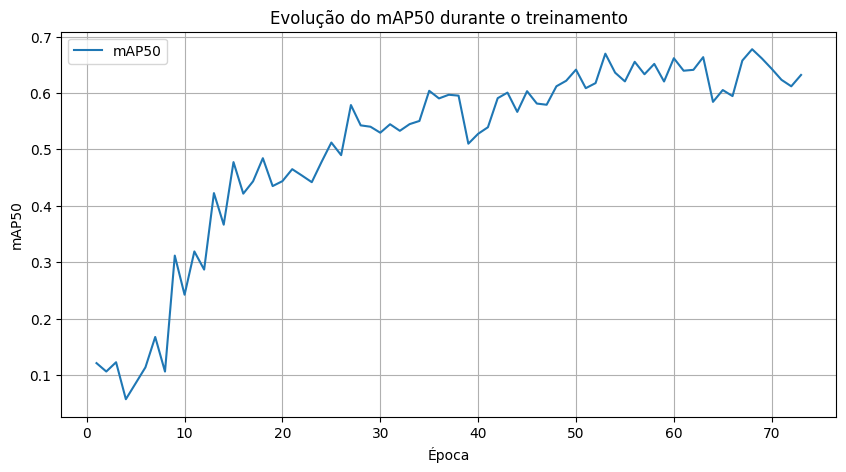

In [20]:
RESULTS_DIR = Path("/content/results/drone_shark_yolo11s_v2")
RESULTS_CSV = RESULTS_DIR / "results.csv"

if RESULTS_CSV.exists():
    history = pd.read_csv(RESULTS_CSV)
    display(history.tail())

    print("Colunas disponíveis:")
    print(list(history.columns))

    # Gráfico de mAP50, se disponível
    if "metrics/mAP50(B)" in history.columns:
        plt.figure(figsize=(10, 5))
        plt.plot(history["epoch"], history["metrics/mAP50(B)"], label="mAP50")
        plt.xlabel("Época")
        plt.ylabel("mAP50")
        plt.title("Evolução do mAP50 durante o treinamento")
        plt.grid(True)
        plt.legend()
        plt.show()
else:
    print("results.csv não encontrado. Execute primeiro o treinamento.")


## 9. Avaliação geral no conjunto de teste

Esta é a avaliação final do modelo em imagens que não participaram do treinamento.


In [21]:
# ===== AVALIAÇÃO FINAL =====

best_model = YOLO(BEST_MODEL)

test_metrics = best_model.val(
    data=DATA_YAML,
    split="test",
    imgsz=640,
    plots=True
)

print("\nResultados gerais:")
for key, value in test_metrics.results_dict.items():
    print(f"{key}: {value}")


Ultralytics 8.4.127 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 101 layers, 9,413,961 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1321.1±804.1 MB/s, size: 115.6 KB)
val: Scanning /content/dataset/labels/test... 68 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 68/68 1.8Kit/s 0.0s
val: New cache created: /content/dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 2.0it/s 2.5s
                   all         68        149      0.563      0.513       0.49      0.211
          human-bather          6          8      0.247      0.125      0.107     0.0539
         human-surfist          8         10      0.789      0.749      0.735      0.304
                 shark         68        131      0.653      0.664      0.628      0.274
Speed: 6.5ms preprocess, 12.9ms inference, 0.0ms loss, 3.0ms postprocess per image
Res

## 10. Resultado por classe

A classe `shark` é a principal variável de interesse do estudo.


In [22]:
# ===== MÉTRICAS POR CLASSE =====

def get_class_metrics(metrics_obj, class_names):
    box = metrics_obj.box

    precision = np.asarray(box.p)
    recall = np.asarray(box.r)
    ap50 = np.asarray(box.ap50)
    ap5095 = np.asarray(box.ap)

    rows = []
    for i, name in enumerate(class_names):
        rows.append({
            "Classe": name,
            "Precision": precision[i] if i < len(precision) else np.nan,
            "Recall": recall[i] if i < len(recall) else np.nan,
            "mAP50": ap50[i] if i < len(ap50) else np.nan,
            "mAP50-95": ap5095[i] if i < len(ap5095) else np.nan
        })

    return pd.DataFrame(rows)

class_results = get_class_metrics(test_metrics, CLASS_NAMES)
display(class_results.style.format({
    "Precision": "{:.4f}",
    "Recall": "{:.4f}",
    "mAP50": "{:.4f}",
    "mAP50-95": "{:.4f}"
}))


,Classe,Precision,Recall,mAP50,mAP50-95
0,human-bather,0.2475,0.1250,0.1067,0.0539
1,human-surfist,0.7887,0.7490,0.7350,0.3041
2,shark,0.6534,0.6641,0.6284,0.2740


## 11. Classificação das condições visuais

Para avaliar o efeito das condições ambientais, cada imagem do conjunto de teste deve receber uma classificação.

### Critérios sugeridos

**Fácil**
- tubarão claramente visível;
- tamanho aparente grande;
- contraste elevado;
- iluminação adequada;
- pouca interferência visual.

**Moderada**
- tamanho intermediário;
- contraste ou iluminação intermediários;
- alguma interferência visual.

**Difícil**
- tubarão pequeno/distante;
- baixo contraste;
- baixa iluminação;
- água visualmente mais turva;
- reflexos, oclusão ou forte interferência visual.

### Importante

A classificação deve ser feita **sem observar as métricas de desempenho**, para evitar viés.

A planilha abaixo é criada automaticamente e deve ser preenchida manualmente antes da avaliação por condição.


In [23]:
# ===== GERAR PLANILHA DE CLASSIFICAÇÃO =====

test_images = sorted([
    p.name for p in Path(f"{DATASET}/images/test").iterdir()
    if p.suffix.lower() in IMAGE_EXTS
])

difficulty_csv = "/content/difficulty_labels.csv"

difficulty_df = pd.DataFrame({
    "image": test_images,
    "difficulty": "",
    "notes": ""
})

difficulty_df.to_csv(difficulty_csv, index=False, encoding="utf-8")

print("Planilha criada:", difficulty_csv)
display(difficulty_df.head(20))

print("\nPreencha a coluna 'difficulty' com: easy, medium ou hard.")


Planilha criada: /content/difficulty_labels.csv


,image,difficulty,notes
0,002af3b9-00731.png,,
1,0150d296-00631.png,,
2,06fa4b2a-004.jpg,,
3,07680d74-00706.png,,
4,07f008dc-00160.jpg,,
5,0e3aeb2e-00639.png,,
6,0fa6300f-00698.png,,
7,11311544-00244.jpg,,
8,18f2c54f-00282.jpg,,
9,1c9fa9b0-00162.jpg,,



Preencha a coluna 'difficulty' com: easy, medium ou hard.


## 12. Contact sheet para auxiliar a classificação

Esta célula cria uma grade com as imagens de teste. Use-a para preencher a planilha `difficulty_labels.csv`.

Depois de preencher a planilha, faça upload dela no Colab ou substitua o arquivo em `/content/`.


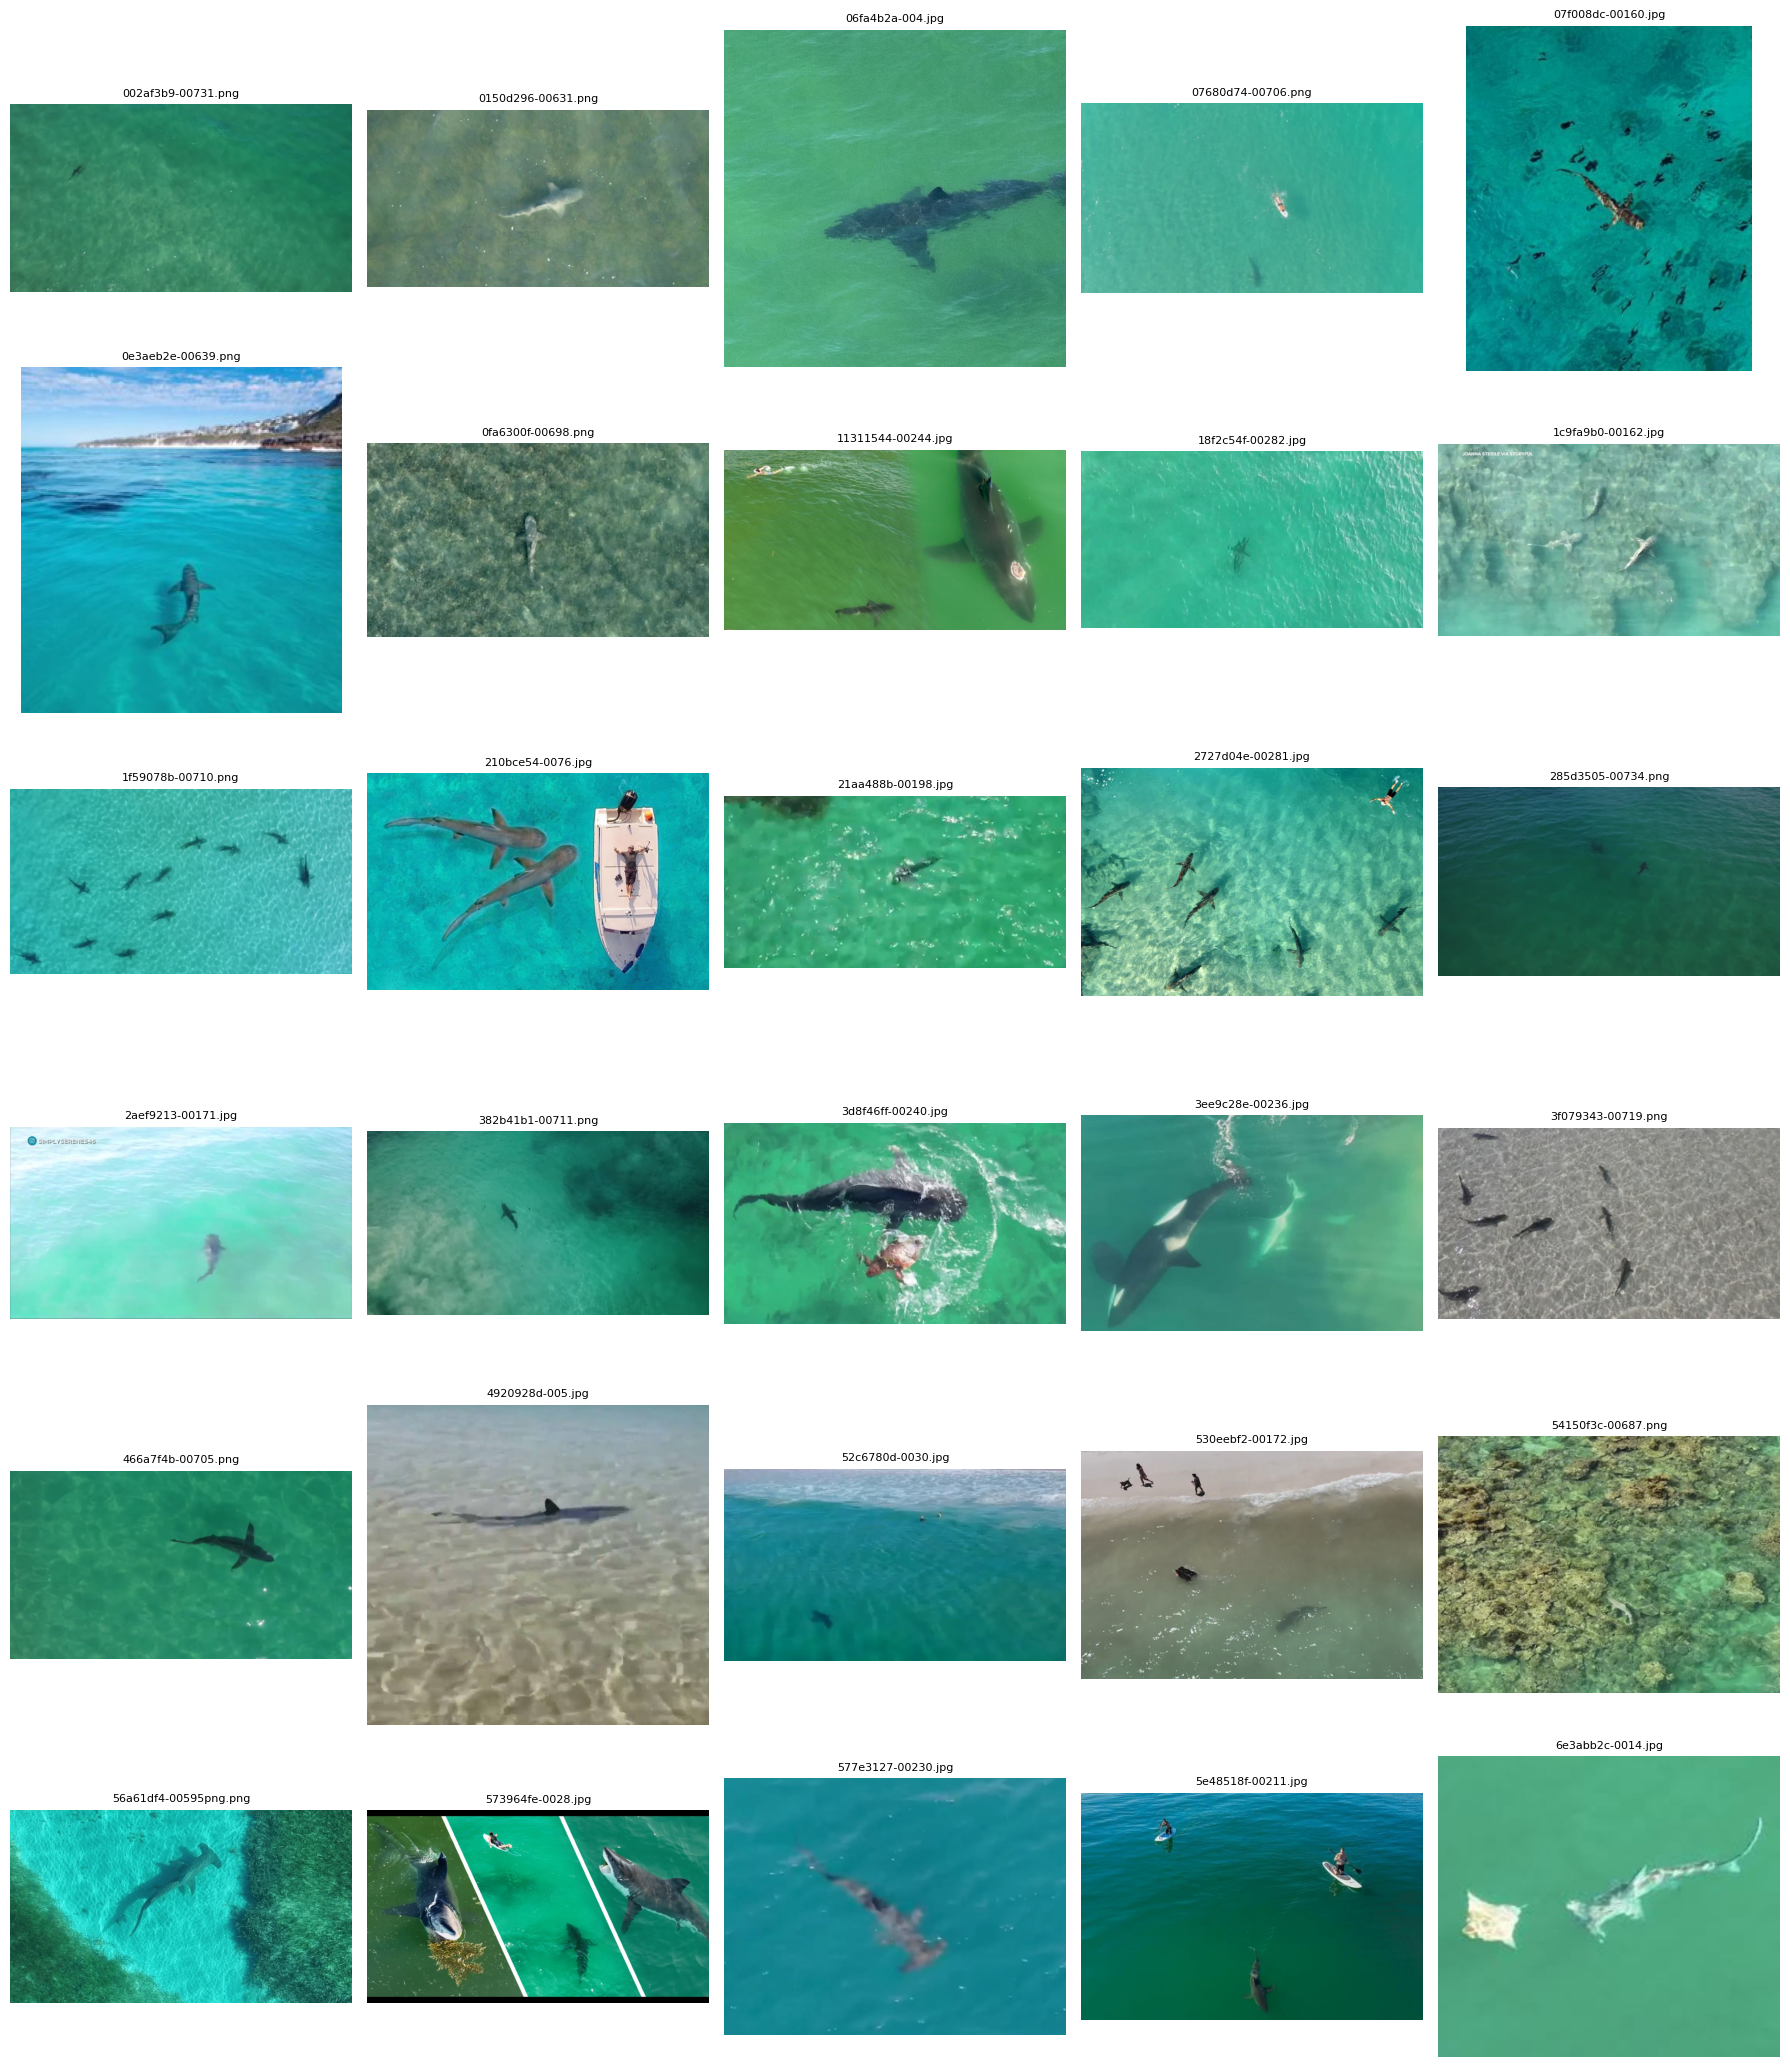

In [24]:
# ===== CONTACT SHEET =====

def create_contact_sheet(split="test", n=30, cols=5):
    image_files = sorted([
        p for p in Path(f"{DATASET}/images/{split}").iterdir()
        if p.suffix.lower() in IMAGE_EXTS
    ])[:n]

    rows = int(np.ceil(len(image_files) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(18, 3.5 * rows))
    axes = np.array(axes).reshape(-1)

    for ax in axes:
        ax.axis("off")

    for ax, img_path in zip(axes, image_files):
        img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
        ax.imshow(img)
        ax.set_title(img_path.name, fontsize=8)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

create_contact_sheet("test", n=30, cols=5)


## 13. Validação da planilha de dificuldade

Antes de executar as métricas por condição, esta célula verifica se todas as imagens de teste receberam uma classificação válida.


In [25]:
from pathlib import Path
from collections import Counter

for split in ["train", "val", "test"]:

    label_dir = Path(f"/content/dataset/labels/{split}")

    counter = Counter()
    invalid = []

    for label_file in label_dir.glob("*.txt"):

        with open(label_file, "r", encoding="utf-8") as f:

            for line_num, line in enumerate(f, start=1):

                if not line.strip():
                    continue

                parts = line.split()

                if len(parts) != 5:
                    invalid.append(
                        (label_file.name, line_num, line.strip())
                    )
                    continue

                class_id = int(float(parts[0]))
                counter[class_id] += 1

                if class_id not in [0, 1, 2]:
                    invalid.append(
                        (label_file.name, line_num, line.strip())
                    )

    print("=" * 60)
    print(f"CONJUNTO: {split}")
    print("=" * 60)
    print("Classes:", dict(counter))
    print("Labels inválidos:", len(invalid))

    if invalid:
        for item in invalid[:10]:
            print(item)

CONJUNTO: train
Classes: {2: 589, 0: 72, 1: 72}
Labels inválidos: 0
CONJUNTO: val
Classes: {2: 122, 0: 19, 1: 18}
Labels inválidos: 0
CONJUNTO: test
Classes: {2: 131, 1: 10, 0: 8}
Labels inválidos: 0


In [26]:
import os
import pandas as pd

# ===== VALIDAR CLASSIFICAÇÃO =====

# Certifique-se de que difficulty_csv e test_images estejam definidos
# (eles são definidos na célula jzKHVEvjVpgJ)

if not os.path.exists(difficulty_csv):
    raise FileNotFoundError(
        "difficulty_labels.csv não encontrado. Execute a célula anterior."
    )

difficulty_df = pd.read_csv(difficulty_csv) # Removido sep=';' para usar o padrão (vírgula)

valid_difficulties = {"easy", "medium", "hard"}

if "image" not in difficulty_df.columns or "difficulty" not in difficulty_df.columns:
    raise ValueError("A planilha precisa conter as colunas: image,difficulty")

difficulty_df["difficulty"] = difficulty_df["difficulty"].astype(str).str.lower().str.strip()

missing_images = sorted(set(test_images) - set(difficulty_df["image"]))
unknown_images = sorted(set(difficulty_df["image"]) - set(test_images)) # Corrigido test_df para test_images
invalid_values = sorted(set(difficulty_df["difficulty"]) - valid_difficulties - {""})

print("Imagens de teste:", len(test_images))
print("Linhas na planilha:", len(difficulty_df))
print("Sem classificação:", (difficulty_df["difficulty"] == "").sum())
print("Imagens não encontradas no teste:", len(unknown_images))
print("Valores inválidos:", invalid_values)

if missing_images:
    print("\nExemplos sem classificação:", missing_images[:10])

if unknown_images:
    print("\nExemplos que não pertencem ao teste:", unknown_images[:10])

if invalid_values:
    raise ValueError("Existem valores inválidos na coluna difficulty.")

if missing_images or unknown_images or invalid_values or (difficulty_df["difficulty"] == "").any():
    print("\n⚠️ Corrija a planilha antes de continuar.")
else:
    print("\n✓ Classificação validada.")
    display(difficulty_df["difficulty"].value_counts())

Imagens de teste: 68
Linhas na planilha: 68
Sem classificação: 0
Imagens não encontradas no teste: 0
Valores inválidos: []

✓ Classificação validada.


,count
difficulty,
medium,27
easy,26
hard,15


## 14. Criação dos subconjuntos Easy / Medium / Hard

As imagens permanecem no conjunto de teste original. Para a avaliação por condição, serão criadas cópias temporárias dos arquivos de imagem e anotação.


In [27]:
# ===== PREPARAR SUBCONJUNTOS =====

SUBSET_ROOT = "/content/test_subsets"

if os.path.exists(SUBSET_ROOT):
    shutil.rmtree(SUBSET_ROOT)

for difficulty in ["easy", "medium", "hard"]:
    os.makedirs(f"{SUBSET_ROOT}/images/{difficulty}", exist_ok=True)
    os.makedirs(f"{SUBSET_ROOT}/labels/{difficulty}", exist_ok=True)

test_img_dir = Path(f"{DATASET}/images/test")
test_label_dir = Path(f"{DATASET}/labels/test")

for _, row in difficulty_df.iterrows():
    img_name = row["image"]
    difficulty = row["difficulty"]

    img_src = test_img_dir / img_name
    label_src = test_label_dir / Path(img_name).with_suffix(".txt").name

    if not img_src.exists():
        continue

    shutil.copy2(img_src, f"{SUBSET_ROOT}/images/{difficulty}/{img_name}")

    if label_src.exists():
        shutil.copy2(
            label_src,
            f"{SUBSET_ROOT}/labels/{difficulty}/{label_src.name}"
        )

print("Subconjuntos criados em:", SUBSET_ROOT)
for d in ["easy", "medium", "hard"]:
    count = len(list(Path(f"{SUBSET_ROOT}/images/{d}").glob("*")))
    print(d, ":", count, "imagens")


Subconjuntos criados em: /content/test_subsets
easy : 26 imagens
medium : 27 imagens
hard : 15 imagens


## 15. Avaliação quantitativa por condição

O mesmo modelo `best.pt` será aplicado separadamente aos grupos Easy, Medium e Hard.

Isso permite responder à pergunta principal:

> **O desempenho do detector varia de acordo com a condição visual da imagem?**


In [28]:
# ===== AVALIAÇÃO POR CONDIÇÃO =====

def create_subset_yaml(difficulty):
    yaml_path = f"{SUBSET_ROOT}/data_{difficulty}.yaml"

    data = {
        "path": SUBSET_ROOT,
        "train": f"images/{difficulty}", # Adicionado para satisfazer o requisito do Ultralytics
        "val": f"images/{difficulty}",
        "nc": len(CLASS_NAMES),
        "names": CLASS_NAMES
    }

    with open(yaml_path, "w", encoding="utf-8") as f:
        yaml.safe_dump(data, f, sort_keys=False, allow_unicode=True)

    return yaml_path

def evaluate_subset(model, difficulty):
    yaml_path = create_subset_yaml(difficulty)

    image_count = len(list(Path(f"{SUBSET_ROOT}/images/{difficulty}").glob("*")))

    if image_count == 0:
        return {
            "Condição": difficulty,
            "Imagens": 0,
            "Precision": np.nan,
            "Recall": np.nan,
            "mAP50": np.nan,
            "mAP50-95": np.nan
        }

    m = model.val(
        data=yaml_path,
        split="val",
        imgsz=640,
        plots=False,
        verbose=False
    )

    return {
        "Condição": difficulty,
        "Imagens": image_count,
        "Precision": m.results_dict.get("metrics/precision(B)", np.nan),
        "Recall": m.results_dict.get("metrics/recall(B)", np.nan),
        "mAP50": m.results_dict.get("metrics/mAP50(B)", np.nan),
        "mAP50-95": m.results_dict.get("metrics/mAP50-95(B)", np.nan)
    }

subset_results = []

for difficulty in ["easy", "medium", "hard"]:
    print(f"Avaliando: {difficulty}")
    subset_results.append(evaluate_subset(best_model, difficulty))

condition_results = pd.DataFrame(subset_results)

display(condition_results.style.format({
    "Precision": "{:.4f}",
    "Recall": "{:.4f}",
    "mAP50": "{:.4f}",
    "mAP50-95": "{:.4f}"
}))

Avaliando: easy
Ultralytics 8.4.127 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2058.1±1362.9 MB/s, size: 105.8 KB)
val: Scanning /content/test_subsets/labels/easy... 26 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 26/26 1.5Kit/s 0.0s
val: New cache created: /content/test_subsets/labels/easy.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.9it/s 0.7s
                   all         26         50      0.829      0.562      0.588      0.303
Speed: 1.3ms preprocess, 12.1ms inference, 0.0ms loss, 1.3ms postprocess per image
Avaliando: medium
Ultralytics 8.4.127 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1972.9±1125.5 MB/s, size: 120.7 KB)
val: Scanning /content/test_subsets/labels/medium... 27 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 27/27 1.8Kit/s 0.0s
val: New ca

,Condição,Imagens,Precision,Recall,mAP50,mAP50-95
0,easy,26,0.8292,0.5620,0.5880,0.3028
1,medium,27,0.4777,0.4262,0.3050,0.1131
2,hard,15,0.5402,0.7037,0.6150,0.2661


## 16. Gráfico comparativo das condições

O gráfico facilita a interpretação da hipótese do estudo.


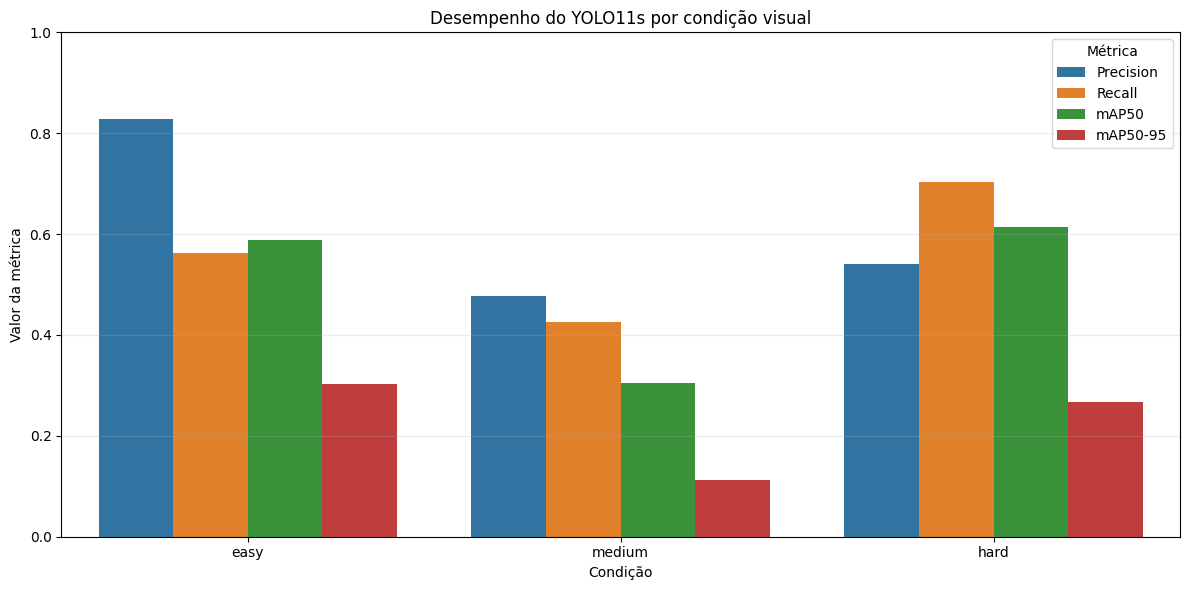

In [29]:
# ===== GRÁFICO =====

plot_df = condition_results.melt(
    id_vars=["Condição", "Imagens"],
    value_vars=["Precision", "Recall", "mAP50", "mAP50-95"],
    var_name="Métrica",
    value_name="Valor"
)

plt.figure(figsize=(12, 6))
sns.barplot(data=plot_df, x="Condição", y="Valor", hue="Métrica")
plt.ylim(0, 1)
plt.title("Desempenho do YOLO11s por condição visual")
plt.xlabel("Condição")
plt.ylabel("Valor da métrica")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


## 17. Análise visual das detecções

Além das métricas, devem ser selecionadas imagens representativas de cada condição para demonstrar:

- detecções corretas;
- falsos positivos;
- falsos negativos;
- dificuldade de localizar tubarões pequenos ou pouco contrastantes.



===== EASY =====


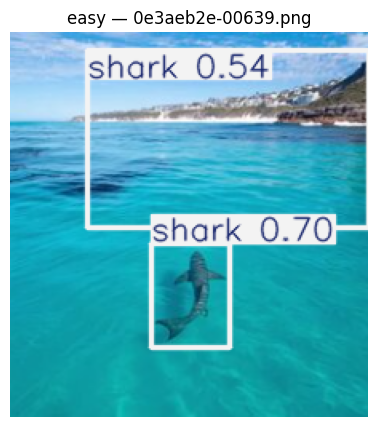

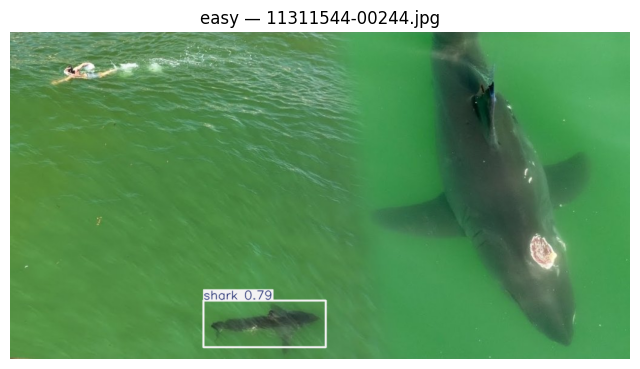

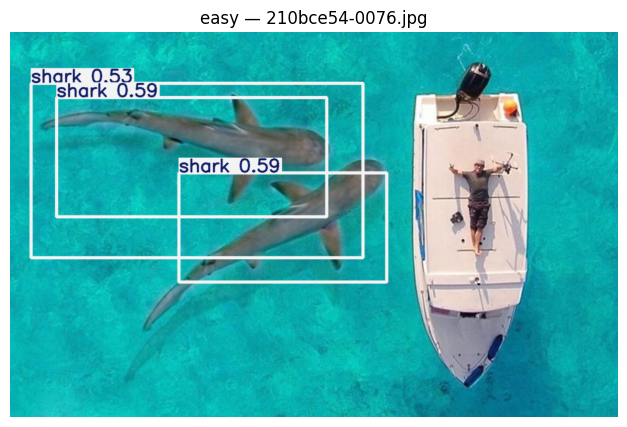


===== MEDIUM =====


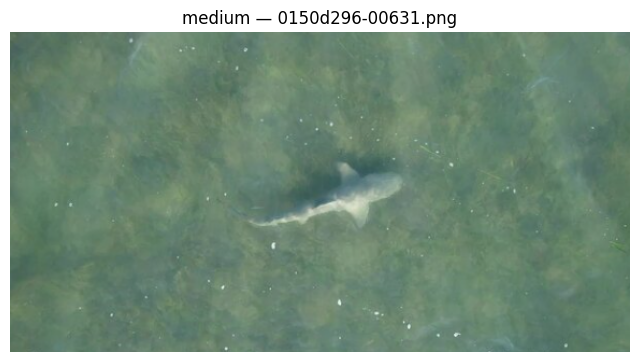

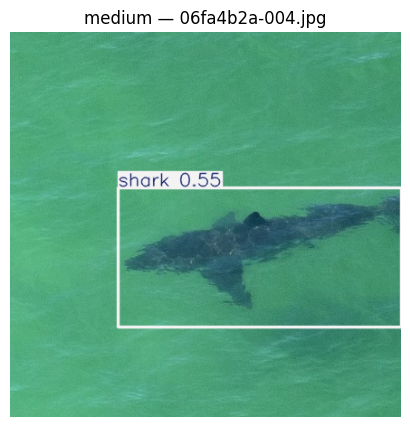

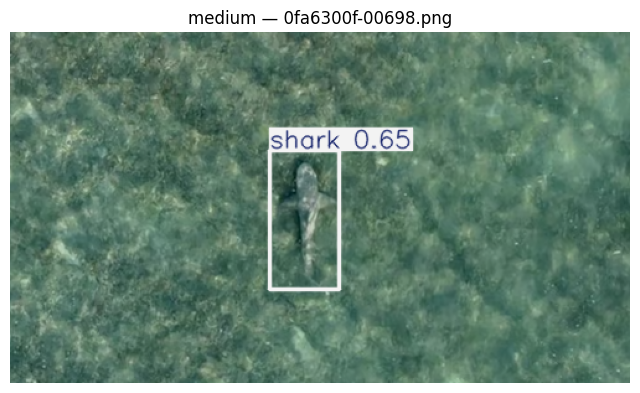


===== HARD =====


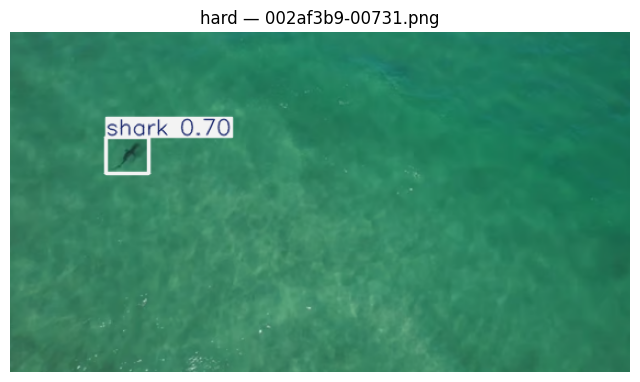

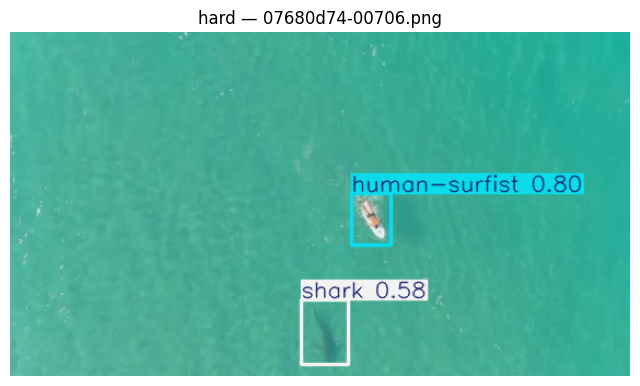

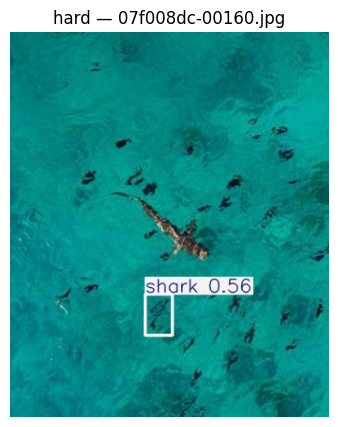

In [30]:
# ===== PREDIÇÕES VISUAIS =====

# Escolha algumas imagens de cada condição.
for difficulty in ["easy", "medium", "hard"]:
    files_ = sorted(Path(f"{SUBSET_ROOT}/images/{difficulty}").glob("*"))[:3]

    print(f"\n===== {difficulty.upper()} =====")

    for img_path in files_:
        preds = best_model.predict(
            source=str(img_path),
            conf=0.50,
            verbose=False
        )

        annotated = preds[0].plot()
        annotated = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)

        plt.figure(figsize=(8, 5))
        plt.imshow(annotated)
        plt.title(f"{difficulty} — {img_path.name}")
        plt.axis("off")
        plt.show()


## 18. Teste aplicado em vídeo

O vídeo é apresentado como demonstração da aplicação prática do modelo. Ele não substitui a avaliação quantitativa realizada no conjunto de teste.


In [ ]:
# ===== DETECÇÃO EM VÍDEO =====

VIDEO_PATH = "/content/video.mp4"  # altere para o caminho do seu vídeo

if os.path.exists(VIDEO_PATH):
    video_results = best_model.predict(
        source=VIDEO_PATH,
        conf=0.50,
        save=True,
        project="/content/video_results",
        name="drone_shark_detection",
        exist_ok=True
    )

    print("Vídeo processado.")
    print("Resultados salvos em /content/video_results")
else:
    print("Vídeo não encontrado. Altere VIDEO_PATH para executar esta etapa.")


Vídeo não encontrado. Altere VIDEO_PATH para executar esta etapa.


## 19. Exportação dos resultados

As tabelas principais podem ser salvas para utilização no TCC.


In [ ]:
# ===== EXPORTAR RESULTADOS =====

class_results.to_csv(
    "/content/resultados_por_classe.csv",
    index=False,
    encoding="utf-8-sig"
)

condition_results.to_csv(
    "/content/resultados_por_condicao.csv",
    index=False,
    encoding="utf-8-sig"
)

difficulty_df.to_csv(
    "/content/difficulty_labels_final.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Arquivos gerados:")
print("/content/resultados_por_classe.csv")
print("/content/resultados_por_condicao.csv")
print("/content/difficulty_labels_final.csv")


Arquivos gerados:
/content/resultados_por_classe.csv
/content/resultados_por_condicao.csv
/content/difficulty_labels_final.csv


# 20. Estrutura para interpretação dos resultados

Ao finalizar a execução, o capítulo do TCC pode ser organizado em:

1. **Ambiente experimental** — Google Colab, GPU, Python e Ultralytics YOLO.
2. **Preparação da base** — divisão 70/15/15 e classes utilizadas.
3. **Treinamento** — YOLO11s e hiperparâmetros fixos.
4. **Avaliação geral** — Precision, Recall, mAP50 e mAP50-95.
5. **Avaliação por condição** — Easy, Medium e Hard.
6. **Análise visual** — exemplos de acertos e erros.
7. **Aplicação em vídeo** — demonstração do detector.
8. **Limitações** — quantidade de imagens, qualidade visual, classificação manual das condições e possíveis dificuldades de generalização.

### Hipótese de interpretação

Se as métricas diminuírem de Easy → Medium → Hard, o resultado fornece evidência de que as condições visuais presentes nas imagens influenciam a capacidade de detecção.

Se isso não acontecer, o resultado também é válido: significa que, dentro da amostra utilizada, não foi observada uma diferença consistente entre os grupos.

**Não altere a classificação das imagens depois de observar os resultados apenas para produzir uma tendência esperada.**
